In [1]:
import pandas as pd
from xgboost import XGBRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error
from sklearn.pipeline import make_pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.model_selection import train_test_split
from matplotlib import pyplot as plt
import numpy as np
import warnings
warnings.filterwarnings("ignore")
train = pd.read_csv("train.csv",parse_dates=["date"])
test = pd.read_csv("test.csv",parse_dates=["date"])
stores = pd.read_csv("stores.csv")
oil = pd.read_csv("oil.csv",parse_dates=["date"])
holidays_events = pd.read_csv("holidays_events.csv",parse_dates=["date"])
transactions = pd.read_csv("transactions.csv",parse_dates=["date"])
sample_subm = pd.read_csv("sample_submission.csv")
print("Dataset loaded successfully")
print("Train:", train.shape)
print("Test:", test.shape)

Dataset loaded successfully
Train: (3000888, 6)
Test: (28512, 5)


In [2]:
train['set'] = 'train'
test['set'] = 'test'
test['sales'] = 0.0

In [3]:
combined = pd.concat([train, test], ignore_index=True)
combined = combined.merge(stores, on='store_nbr', how='left')
combined = combined.merge(oil, on='date', how='left')
combined = combined.merge(holidays_events[['date','type']], on='date', how='left')
combined = combined.merge(transactions, on=['date', 'store_nbr'], how='left')

combined['date']       = pd.to_datetime(combined['date'])
combined['store_nbr']  = combined['store_nbr'].astype(str)

combined.rename(columns={'dcoilwtico': 'daily_oil_prices'}, inplace=True)
combined['daily_oil_prices'].fillna(method='bfill', inplace=True)

combined['is_holiday'] = combined['type_x'].notna()
combined['cluster'] = combined['cluster'].astype(str)
combined['store_city'] = combined['city'] + '_' + combined['state'] + '_' + combined['type_x']+combined['cluster']
combined['daily_oil_prices'].fillna(method='bfill', inplace=True)
combined['transactions'] = combined['transactions'].interpolate(method='nearest')
combined['transactions'].fillna(method='ffill', inplace=True)
combined['transactions'].fillna(method='bfill', inplace=True)
combined.drop(columns=['city','state','type_x','cluster','type_y'],inplace=True)
combined.head(5)

,id,date,store_nbr,family,sales,onpromotion,set,daily_oil_prices,transactions,is_holiday,store_city
0,0,2013-01-01,1,AUTOMOTIVE,0.0,0,train,93.14,770.0,True,Quito_Pichincha_D13
1,1,2013-01-01,1,BABY CARE,0.0,0,train,93.14,770.0,True,Quito_Pichincha_D13
2,2,2013-01-01,1,BEAUTY,0.0,0,train,93.14,770.0,True,Quito_Pichincha_D13
3,3,2013-01-01,1,BEVERAGES,0.0,0,train,93.14,770.0,True,Quito_Pichincha_D13
4,4,2013-01-01,1,BOOKS,0.0,0,train,93.14,770.0,True,Quito_Pichincha_D13


In [4]:
def missing_values(df, name):
    missing = df.isnull().sum()
    missing = missing[missing > 0]
    if not missing.empty:
        print(f"Missing values in {name}:")
        print(missing)
        print("\n")
    else:
        print(f"No missing values in {name}.\n")

missing_values(combined, 'combined')

No missing values in combined.



In [5]:
train_final = combined[combined['set'] == 'train'].drop(columns=['set'])
test_final = combined[combined['set'] == 'test'].drop(columns=['set', 'sales'])

In [6]:
train_final.head(5)

,id,date,store_nbr,family,sales,onpromotion,daily_oil_prices,transactions,is_holiday,store_city
0,0,2013-01-01,1,AUTOMOTIVE,0.0,0,93.14,770.0,True,Quito_Pichincha_D13
1,1,2013-01-01,1,BABY CARE,0.0,0,93.14,770.0,True,Quito_Pichincha_D13
2,2,2013-01-01,1,BEAUTY,0.0,0,93.14,770.0,True,Quito_Pichincha_D13
3,3,2013-01-01,1,BEVERAGES,0.0,0,93.14,770.0,True,Quito_Pichincha_D13
4,4,2013-01-01,1,BOOKS,0.0,0,93.14,770.0,True,Quito_Pichincha_D13


In [7]:
test_final.head(5)

,id,date,store_nbr,family,onpromotion,daily_oil_prices,transactions,is_holiday,store_city
3054348,3000888,2017-08-16,1,AUTOMOTIVE,0,46.8,2155.0,True,Quito_Pichincha_D13
3054349,3000889,2017-08-16,1,BABY CARE,0,46.8,2155.0,True,Quito_Pichincha_D13
3054350,3000890,2017-08-16,1,BEAUTY,2,46.8,2155.0,True,Quito_Pichincha_D13
3054351,3000891,2017-08-16,1,BEVERAGES,20,46.8,2155.0,True,Quito_Pichincha_D13
3054352,3000892,2017-08-16,1,BOOKS,0,46.8,2155.0,True,Quito_Pichincha_D13


In [8]:
print(train_final['family'].unique())
print(train_final['store_nbr'].unique())
print(len(train_final['family'].unique()))
print(len(train_final['store_nbr'].unique()))

['AUTOMOTIVE' 'BABY CARE' 'BEAUTY' 'BEVERAGES' 'BOOKS' 'BREAD/BAKERY'
 'CELEBRATION' 'CLEANING' 'DAIRY' 'DELI' 'EGGS' 'FROZEN FOODS' 'GROCERY I'
 'GROCERY II' 'HARDWARE' 'HOME AND KITCHEN I' 'HOME AND KITCHEN II'
 'HOME APPLIANCES' 'HOME CARE' 'LADIESWEAR' 'LAWN AND GARDEN' 'LINGERIE'
 'LIQUOR,WINE,BEER' 'MAGAZINES' 'MEATS' 'PERSONAL CARE' 'PET SUPPLIES'
 'PLAYERS AND ELECTRONICS' 'POULTRY' 'PREPARED FOODS' 'PRODUCE'
 'SCHOOL AND OFFICE SUPPLIES' 'SEAFOOD']
['1' '10' '11' '12' '13' '14' '15' '16' '17' '18' '19' '2' '20' '21' '22'
 '23' '24' '25' '26' '27' '28' '29' '3' '30' '31' '32' '33' '34' '35' '36'
 '37' '38' '39' '4' '40' '41' '42' '43' '44' '45' '46' '47' '48' '49' '5'
 '50' '51' '52' '53' '54' '6' '7' '8' '9']
33
54


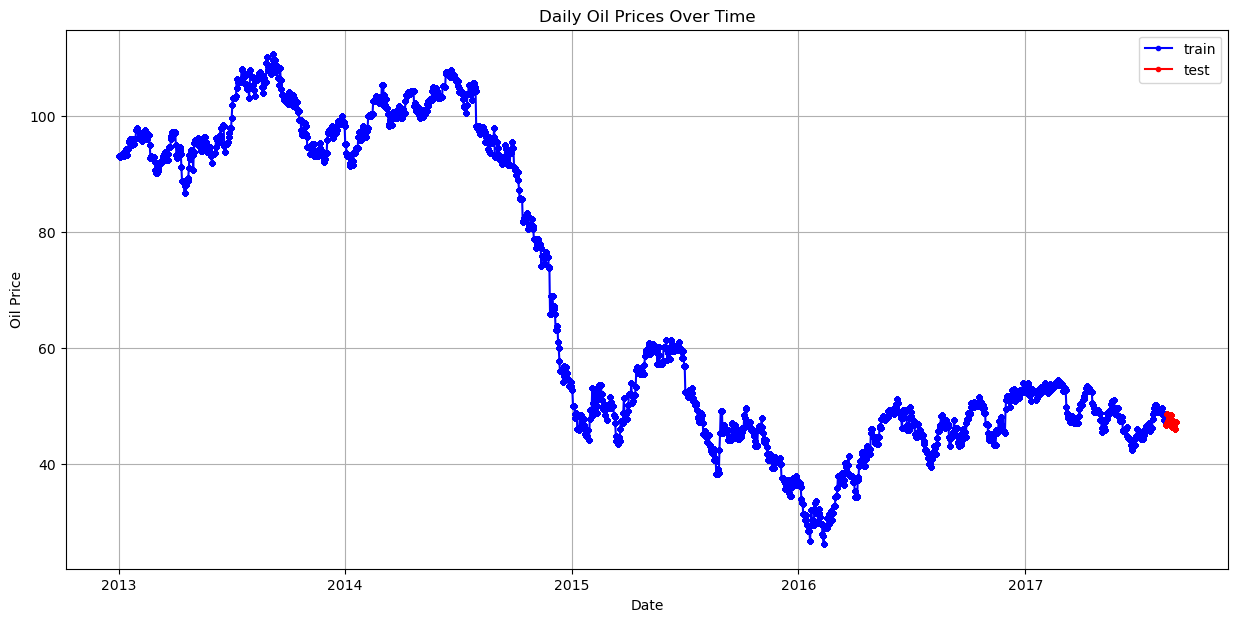

In [9]:
plt.figure(figsize=(15,7))
plt.plot(train_final['date'], train_final['daily_oil_prices'], label='train', color='blue', marker='.')
plt.plot(test_final['date'], test_final['daily_oil_prices'], label='test', color='red', marker='.')

# Add labels, legend, and title
plt.title('Daily Oil Prices Over Time')
plt.xlabel('Date')
plt.ylabel('Oil Price')
plt.legend()
plt.grid()
plt.show()

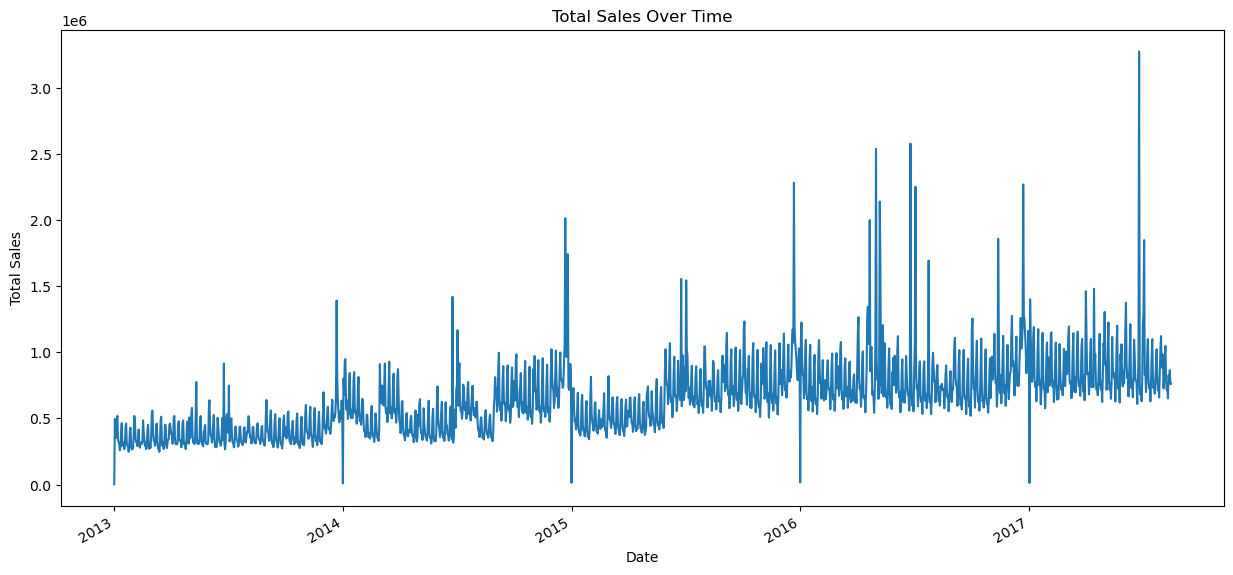

In [10]:
plt.figure(figsize=(15,7))
train_final.groupby('date')['sales'].sum().plot()
plt.title('Total Sales Over Time')
plt.xlabel('Date')
plt.ylabel('Total Sales')
plt.show()

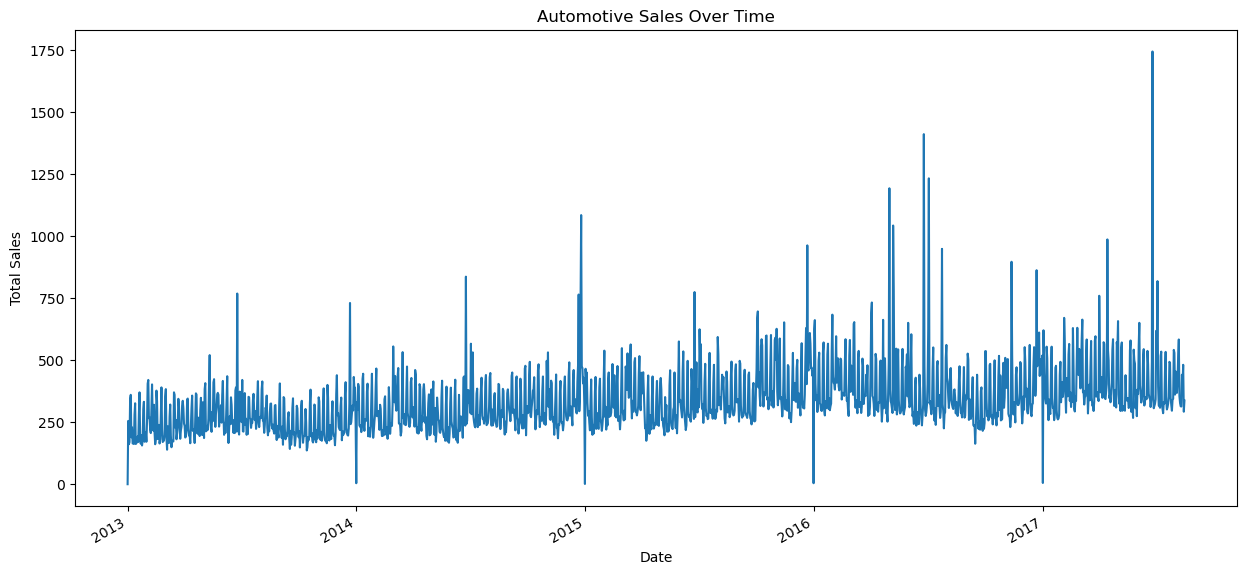

In [11]:
plt.figure(figsize=(15,7))
train_final[train_final['family']=='AUTOMOTIVE'].groupby('date')['sales'].sum().plot()
plt.title('Automotive Sales Over Time')
plt.xlabel('Date')
plt.ylabel('Total Sales')
plt.show()

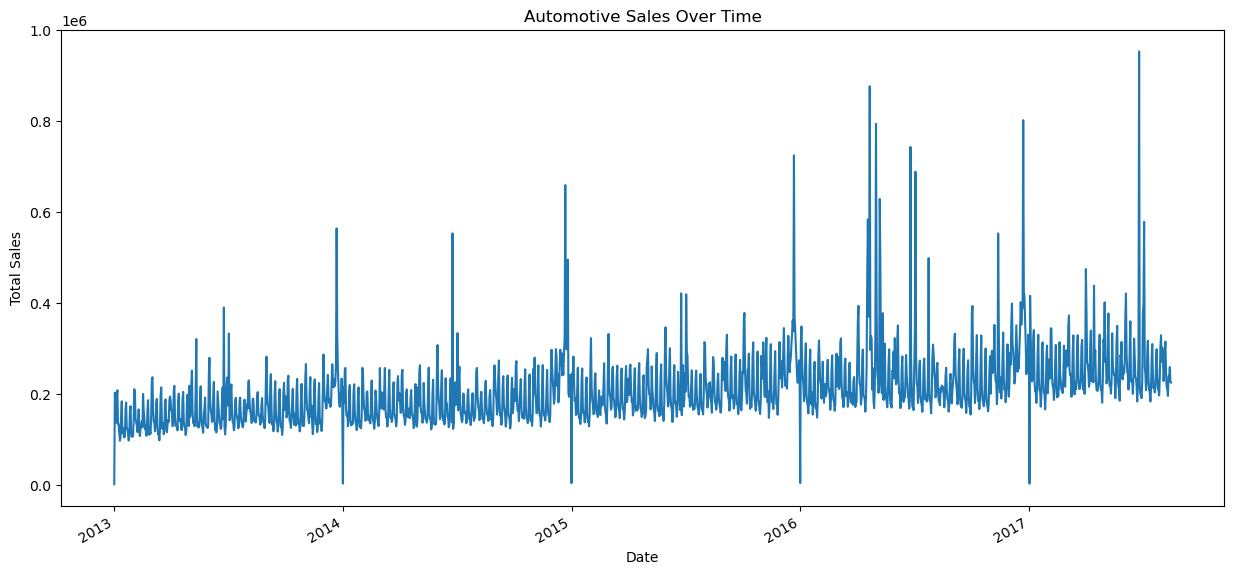

In [12]:
plt.figure(figsize=(15,7))
train_final[train_final['family']=='GROCERY I'].groupby('date')['sales'].sum().plot()
plt.title('Automotive Sales Over Time')
plt.xlabel('Date')
plt.ylabel('Total Sales')
plt.show()

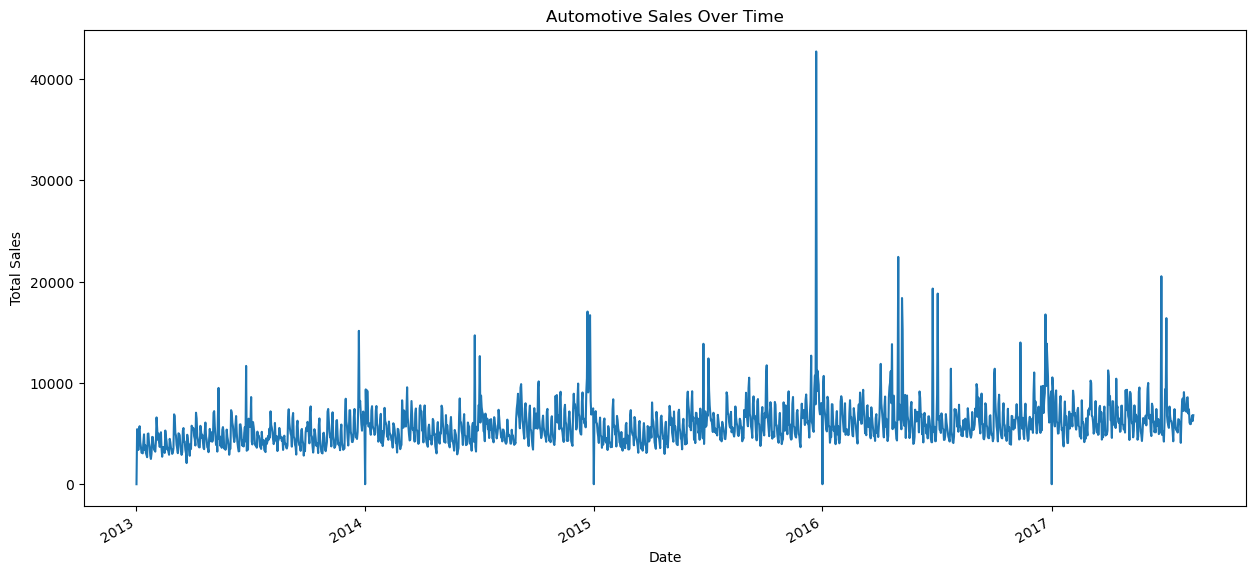

In [13]:
plt.figure(figsize=(15,7))
train_final[train_final['store_nbr']=='10'].groupby('date')['sales'].sum().plot()
plt.title('Automotive Sales Over Time')
plt.xlabel('Date')
plt.ylabel('Total Sales')
plt.show()

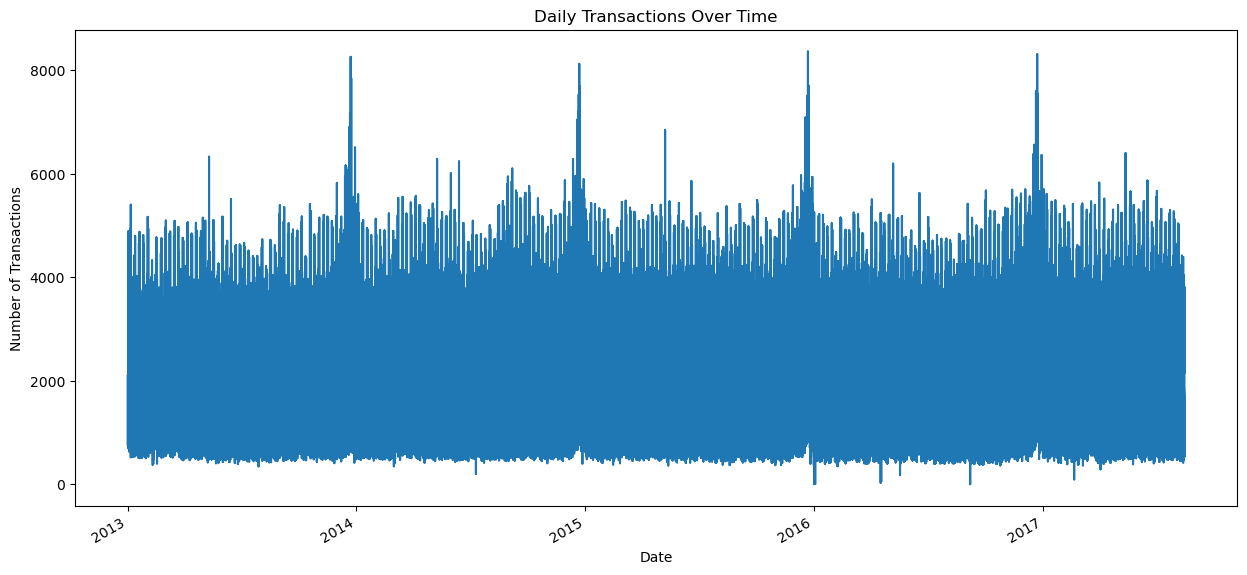

In [14]:
plt.figure(figsize=(15,7))
train_final.set_index('date')['transactions'].plot()
plt.title('Daily Transactions Over Time')
plt.xlabel('Date')
plt.ylabel('Number of Transactions')
plt.show()

In [15]:
print('Training Starting date:',train_final['date'].min())
print('Training Ending date:',train_final['date'].max())
print('Testing Starting date:',test_final['date'].min())
print('Testing Ending date:',test_final['date'].max())

Training Starting date: 2013-01-01 00:00:00
Training Ending date: 2017-08-15 00:00:00
Testing Starting date: 2017-08-16 00:00:00
Testing Ending date: 2017-08-31 00:00:00


In [16]:
train_final['lag_1'] = train_final.groupby(['store_nbr', 'family'])['sales'].shift(1)
train_final['rolling_mean_7'] = train_final.groupby(['store_nbr', 'family'])['sales'].transform(lambda x: x.rolling(7).mean())
train_final.fillna(0, inplace=True)

train_final.head(5)

,id,date,store_nbr,family,sales,onpromotion,daily_oil_prices,transactions,is_holiday,store_city,lag_1,rolling_mean_7
0,0,2013-01-01,1,AUTOMOTIVE,0.0,0,93.14,770.0,True,Quito_Pichincha_D13,0.0,0.0
1,1,2013-01-01,1,BABY CARE,0.0,0,93.14,770.0,True,Quito_Pichincha_D13,0.0,0.0
2,2,2013-01-01,1,BEAUTY,0.0,0,93.14,770.0,True,Quito_Pichincha_D13,0.0,0.0
3,3,2013-01-01,1,BEVERAGES,0.0,0,93.14,770.0,True,Quito_Pichincha_D13,0.0,0.0
4,4,2013-01-01,1,BOOKS,0.0,0,93.14,770.0,True,Quito_Pichincha_D13,0.0,0.0


In [17]:
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), ['onpromotion','daily_oil_prices', 'lag_1', 'rolling_mean_7']),
        ('cat', OneHotEncoder(handle_unknown='ignore'), ['store_nbr','family', 'store_city', 'is_holiday'])
    ]
)

model = make_pipeline(preprocessor, XGBRegressor(n_estimators=100, learning_rate=0.1, random_state=0))

features = ['store_nbr', 'family', 'onpromotion', 'is_holiday','daily_oil_prices', 'store_city', 'lag_1', 'rolling_mean_7']
X = train_final[features]
y = train_final['sales']

X_train, X_valid, y_train, y_valid = train_test_split(X, y, test_size=0.2, random_state=0)
model.fit(X_train, y_train)
predictions = model.predict(X_valid)

mae = mean_absolute_error(y_valid, predictions)
rmse = np.sqrt(mean_squared_error(y_valid, predictions))
print(f'Validation RMSE with selected features: {rmse}')
print(f'Mean Absolute Error: {mae:.2f}')

Validation RMSE with selected features: 312.20296855717083
Mean Absolute Error: 76.70


In [18]:
X_test = test_final.copy()

In [19]:
last_known_sales = train_final.groupby(['store_nbr', 'family'])['sales'].last().reset_index()
last_known_sales.head(5)

,store_nbr,family,sales
0,1,AUTOMOTIVE,4.0
1,1,BABY CARE,0.0
2,1,BEAUTY,4.0
3,1,BEVERAGES,1942.0
4,1,BOOKS,0.0


In [20]:
X_test = X_test.merge(last_known_sales, on=['store_nbr', 'family'], how='left', suffixes=('', '_last'))
X_test['lag_1'] = X_test['sales']
X_test.drop(columns=['sales'], inplace=True)
X_test.head(5)

,id,date,store_nbr,family,onpromotion,daily_oil_prices,transactions,is_holiday,store_city,lag_1
0,3000888,2017-08-16,1,AUTOMOTIVE,0,46.8,2155.0,True,Quito_Pichincha_D13,4.0
1,3000889,2017-08-16,1,BABY CARE,0,46.8,2155.0,True,Quito_Pichincha_D13,0.0
2,3000890,2017-08-16,1,BEAUTY,2,46.8,2155.0,True,Quito_Pichincha_D13,4.0
3,3000891,2017-08-16,1,BEVERAGES,20,46.8,2155.0,True,Quito_Pichincha_D13,1942.0
4,3000892,2017-08-16,1,BOOKS,0,46.8,2155.0,True,Quito_Pichincha_D13,0.0


In [21]:
rolling_means = (
    train_final.groupby(['store_nbr', 'family'])['sales']
    .apply(lambda x: x.rolling(7).mean().iloc[-1])
    .reset_index(name='rolling_mean_7')
)
X_test = X_test.merge(rolling_means, on=['store_nbr', 'family'], how='left')
X_test['rolling_mean_7'].fillna(0, inplace=True)
X_test.head(5)

,id,date,store_nbr,family,onpromotion,daily_oil_prices,transactions,is_holiday,store_city,lag_1,rolling_mean_7
0,3000888,2017-08-16,1,AUTOMOTIVE,0,46.8,2155.0,True,Quito_Pichincha_D13,4.0,4.142857
1,3000889,2017-08-16,1,BABY CARE,0,46.8,2155.0,True,Quito_Pichincha_D13,0.0,0.000000
2,3000890,2017-08-16,1,BEAUTY,2,46.8,2155.0,True,Quito_Pichincha_D13,4.0,4.142857
3,3000891,2017-08-16,1,BEVERAGES,20,46.8,2155.0,True,Quito_Pichincha_D13,1942.0,1757.000000
4,3000892,2017-08-16,1,BOOKS,0,46.8,2155.0,True,Quito_Pichincha_D13,0.0,0.000000


In [22]:
X_test['sales'] = 0 

In [ ]:
for date in sorted(X_test['date'].unique()):
    current_test = X_test[X_test['date'] == date]

    # Select features for prediction
    features = ['store_nbr', 'family', 'onpromotion', 'is_holiday', 'daily_oil_prices', 
                'store_city', 'lag_1', 'rolling_mean_7']

    # Predict sales
    current_test['sales'] = model.predict(current_test[features])

    # Update lag_1 and rolling_mean_7 for future dates
    for idx, row in current_test.iterrows():
        # Update lag_1
        X_test.loc[
            (X_test['store_nbr'] == row['store_nbr']) &
            (X_test['family'] == row['family']) &
            (X_test['date'] > date),
            'lag_1'
        ] = row['sales']

        # Update rolling_mean_7
        recent_sales = (
            X_test[
                (X_test['store_nbr'] == row['store_nbr']) &
                (X_test['family'] == row['family']) &
                (X_test['date'] <= date)
            ]['sales']
            .tail(6).tolist() + [row['sales']]
        )
        rolling_mean = sum(recent_sales) / len(recent_sales)
        X_test.loc[
            (X_test['store_nbr'] == row['store_nbr']) &
            (X_test['family'] == row['family']) &
            (X_test['date'] > date),
            'rolling_mean_7'
        ] = rolling_mean

In [ ]:
# Finalize predictions for submission
submission = X_test[['id', 'sales']]
submission['sales'] = submission['sales'].apply(lambda x: abs(int(x)))
submission.to_csv('submission.csv', index=False)

In [ ]:
train_grouped= train_final.groupby('date')['sales'].sum().reset_index()
train_grouped.head(5)

,date,sales
0,2013-01-01,2511.618999
1,2013-01-02,496092.417944
2,2013-01-03,361461.231124
3,2013-01-04,354459.677093
4,2013-01-05,477350.121229


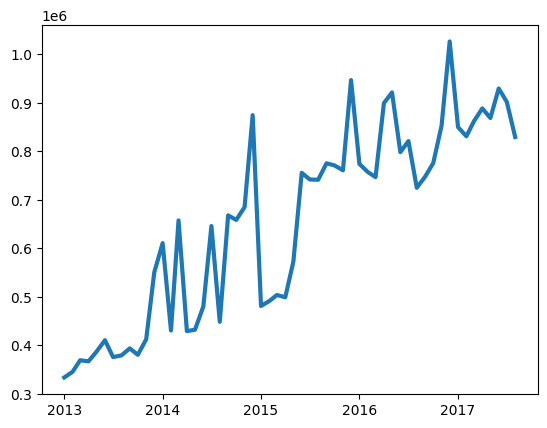

In [ ]:
monthly_data = pd.DataFrame()

train_grouped['date'] = pd.to_datetime(train_grouped['date'])
train_grouped= train_grouped.set_index('date')

monthly_data['sales'] = train_grouped['sales'].resample('MS').mean()
plt.plot(monthly_data.index, monthly_data.sales, linewidth=3)

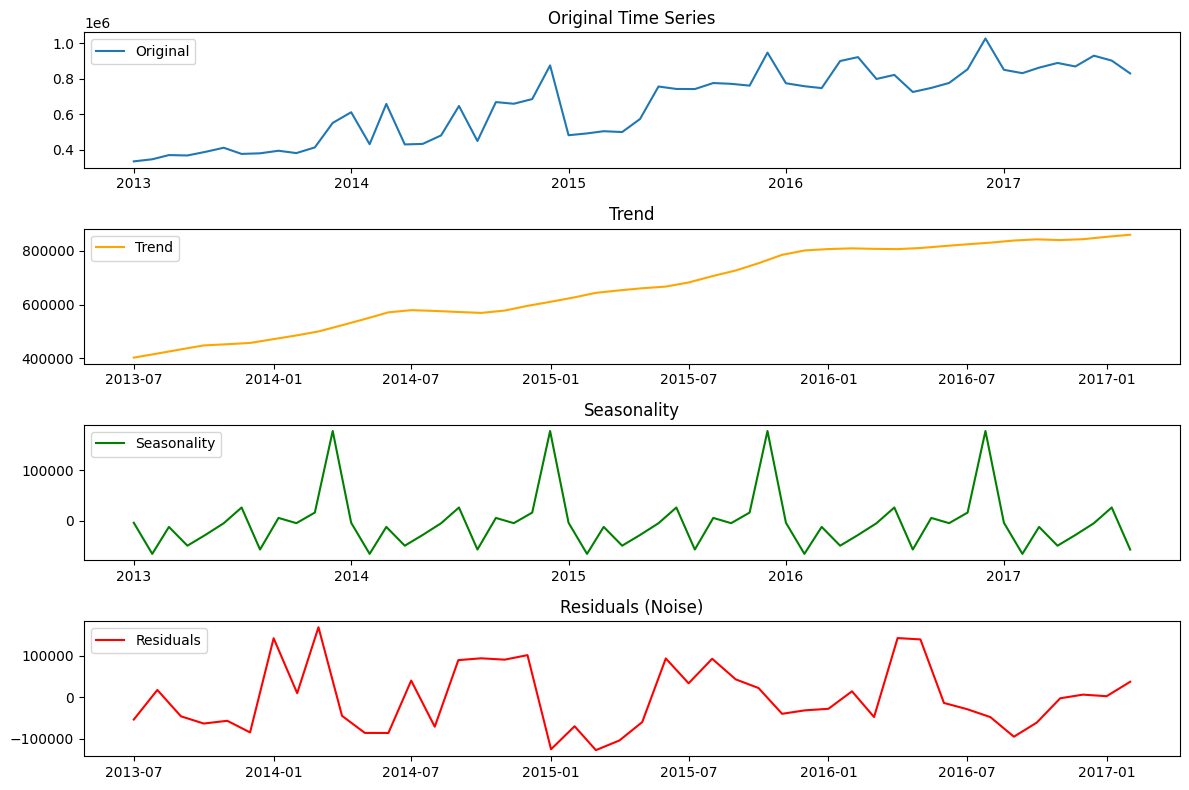

In [ ]:
from statsmodels.tsa.seasonal import seasonal_decompose

decomposed = seasonal_decompose(monthly_data['sales'], model='additive', period=12)
trend = decomposed.trend
seasonality = decomposed.seasonal
residual = decomposed.resid

plt.figure(figsize=(12, 8))

plt.subplot(411)
plt.plot(monthly_data['sales'], label='Original')
plt.title('Original Time Series')
plt.legend(loc='upper left')

plt.subplot(412)
plt.plot(trend, label='Trend', color='orange')
plt.title('Trend')
plt.legend(loc='upper left')

plt.subplot(413)
plt.plot(seasonality, label='Seasonality', color='green')
plt.title('Seasonality')
plt.legend(loc='upper left')

plt.subplot(414)
plt.plot(residual, label='Residuals', color='red')
plt.title('Residuals (Noise)')
plt.legend(loc='upper left')

plt.tight_layout()
plt.show()

In [ ]:
monthly_data['differenced'] = monthly_data['sales'].diff()  # Difference with lag=1

#window = 12  # Adjust for yearly trend (12 months)
#monthly_data['rolling_mean'] = monthly_data['sales'].rolling(window=window).mean()
#monthly_data['detrended'] = monthly_data['sales'] - monthly_data['rolling_mean']

In [ ]:
monthly_data['month'] = monthly_data.index.month
monthly_data['seasonally_adjusted'] = monthly_data['differenced'] - monthly_data.groupby('month')['sales'].transform('mean')

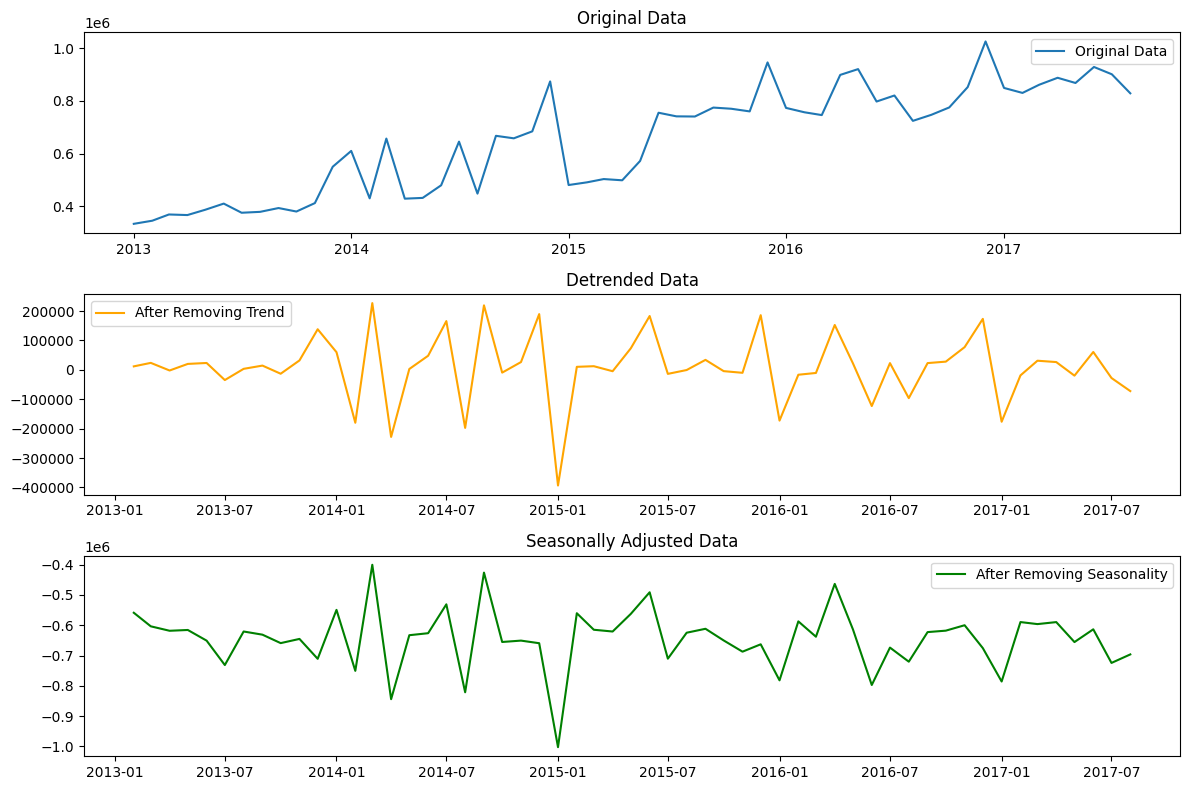

In [ ]:
plt.figure(figsize=(12, 8))

# Original series
plt.subplot(311)
plt.plot(monthly_data['sales'], label='Original Data')
plt.title('Original Data')
plt.legend()

# Detrended series
plt.subplot(312)
plt.plot(monthly_data['differenced'], label='After Removing Trend', color='orange')
plt.title('Detrended Data')
plt.legend()

# Seasonally adjusted series
plt.subplot(313)
plt.plot(monthly_data['seasonally_adjusted'], label='After Removing Seasonality', color='green')
plt.title('Seasonally Adjusted Data')
plt.legend()

plt.tight_layout()
plt.show()

In [ ]:
from statsmodels.tsa.stattools import adfuller

result = adfuller(monthly_data['sales'].dropna())
print(f'ADF Statistic original: {result[0]}')
print(f'p-value original: {result[1]}')

result = adfuller(monthly_data['seasonally_adjusted'].dropna())
print(f'ADF Statistic detrended-no season: {result[0]}')
print(f'p-value detrended-no season: {result[1]}')

ADF Statistic original: -1.7563871474015744
p-value original: 0.402318962086541
ADF Statistic detrended-no season: -5.7027225090871
p-value detrended-no season: 7.610357522711397e-07


 This problem is unconstrained.


RUNNING THE L-BFGS-B CODE

           * * *

Machine precision = 2.220D-16
 N =            5     M =           10

At X0         0 variables are exactly at the bounds

At iterate    0    f=  1.01738D+01    |proj g|=  1.32054D-01

At iterate    5    f=  1.00767D+01    |proj g|=  1.06868D-02

At iterate   10    f=  1.00752D+01    |proj g|=  1.40487D-03

At iterate   15    f=  1.00721D+01    |proj g|=  4.19331D-02

At iterate   20    f=  1.00633D+01    |proj g|=  1.38451D-03

           * * *

Tit   = total number of iterations
Tnf   = total number of function evaluations
Tnint = total number of segments explored during Cauchy searches
Skip  = number of BFGS updates skipped
Nact  = number of active bounds at final generalized Cauchy point
Projg = norm of the final projected gradient
F     = final function value

           * * *

   N    Tit     Tnf  Tnint  Skip  Nact     Projg        F
    5     23     33      1     0     0   5.124D-06   1.006D+01
  F =   10.063303021817147     

CONVERG

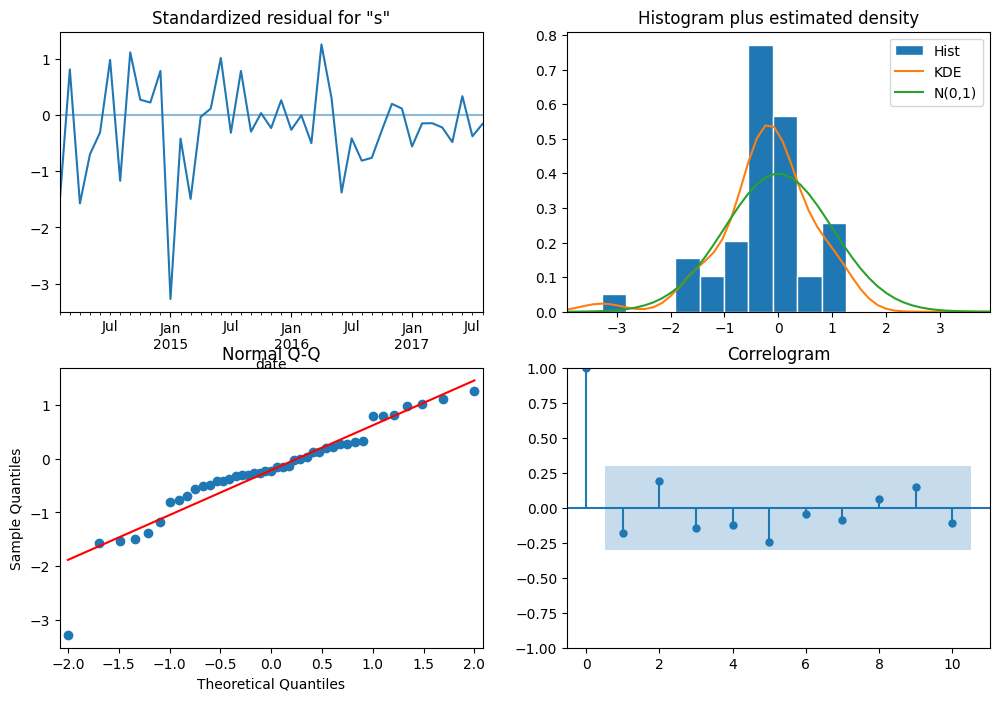

In [ ]:
from statsmodels.tsa.statespace.sarimax import SARIMAX

model = SARIMAX(monthly_data['sales'], order=(1, 1, 1), seasonal_order=(1, 1, 1, 12))
results = model.fit()

print(results.summary())
results.plot_diagnostics(figsize=(12, 8))
plt.show()

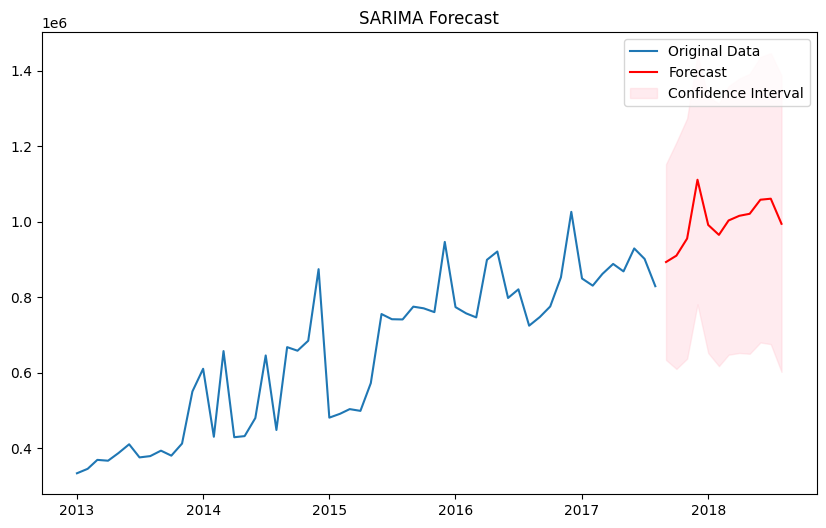

In [ ]:
forecast = results.get_forecast(steps=12)
forecast_values = forecast.predicted_mean
forecast_conf_int = forecast.conf_int()

# Plot the original series with the forecast
plt.figure(figsize=(10, 6))
plt.plot(monthly_data['sales'], label='Original Data')
plt.plot(forecast_values, label='Forecast', color='red')
plt.fill_between(forecast_values.index, 
                 forecast_conf_int.iloc[:, 0], 
                 forecast_conf_int.iloc[:, 1], 
                 color='pink', alpha=0.3, label='Confidence Interval')
plt.legend()
plt.title('SARIMA Forecast')
plt.show()

In [ ]:
forecast_values.head(5)

2017-09-01    8.929528e+05
2017-10-01    9.098439e+05
2017-11-01    9.551692e+05
2017-12-01    1.110988e+06
2018-01-01    9.912228e+05
Freq: MS, Name: predicted_mean, dtype: float64